# CS224N Assignment 1: Exploring Word Vectors (25 Points)
### <font color='blue'> Due 4:30pm, Tue April 9th 2024</font>

Welcome to CS224N! 

Before you start, make sure you **read the README.md** in the same directory as this notebook for important setup information. You need to install some Python libraries before you can successfully do this assignment. A lot of code is provided in this notebook, and we highly encourage you to read and understand it as part of the learning :)

If you aren't super familiar with Python, Numpy, or Matplotlib, we recommend you check out the review session on Friday. The session will be recorded and the material will be made available on our [website](http://web.stanford.edu/class/cs224n/index.html#schedule). The CS231N Python/Numpy [tutorial](https://cs231n.github.io/python-numpy-tutorial/) is also a great resource.


**Assignment Notes:** Please make sure to save the notebook as you go along. Submission Instructions are located at the bottom of the notebook.

In [1]:
# All Import Statements Defined Here
# Note: Do not add to this list.
# ----------------

import sys
assert sys.version_info[0] == 3
assert sys.version_info[1] >= 8

from platform import python_version
assert int(python_version().split(".")[1]) >= 5, "Please upgrade your Python version following the instructions in \
    the README.md file found in the same directory as this notebook. Your Python version is " + python_version()

from gensim.models import KeyedVectors
from gensim.test.utils import datapath
import pprint
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [10, 5]

from datasets import load_dataset
imdb_dataset = load_dataset("stanfordnlp/imdb")

import re
import numpy as np
import random
import scipy as sp
from sklearn.decomposition import TruncatedSVD
from sklearn.decomposition import PCA

START_TOKEN = '<START>'
END_TOKEN = '<END>'
NUM_SAMPLES = 150

np.random.seed(0)
random.seed(0)
# ----------------

/home/zzy/study/cs224n/assignment1/a1/student/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Generating unsupervised split: 100%|██████████| 50000/50000 [00:00<00:00, 152516.37 examples/s]


## Word Vectors

Word Vectors are often used as a fundamental component for downstream NLP tasks, e.g. question answering, text generation, translation, etc., so it is important to build some intuitions as to their strengths and weaknesses. Here, you will explore two types of word vectors: those derived from *co-occurrence matrices*, and those derived via *GloVe*. 

**Note on Terminology:** The terms "word vectors" and "word embeddings" are often used interchangeably. The term "embedding" refers to the fact that we are encoding aspects of a word's meaning in a lower dimensional space. As [Wikipedia](https://en.wikipedia.org/wiki/Word_embedding) states, "*conceptually it involves a mathematical embedding from a space with one dimension per word to a continuous vector space with a much lower dimension*".

## Part 1: Count-Based Word Vectors (10 points)

Most word vector models start from the following idea:

*You shall know a word by the company it keeps ([Firth, J. R. 1957:11](https://en.wikipedia.org/wiki/John_Rupert_Firth))*

Many word vector implementations are driven by the idea that similar words, i.e., (near) synonyms, will be used in similar contexts. As a result, similar words will often be spoken or written along with a shared subset of words, i.e., contexts. By examining these contexts, we can try to develop embeddings for our words. With this intuition in mind, many "old school" approaches to constructing word vectors relied on word counts. Here we elaborate upon one of those strategies, *co-occurrence matrices* (for more information, see [here](https://web.stanford.edu/~jurafsky/slp3/6.pdf) or [here](https://web.archive.org/web/20190530091127/https://medium.com/data-science-group-iitr/word-embedding-2d05d270b285)).

### Co-Occurrence

A co-occurrence matrix counts how often things co-occur in some environment. Given some word $w_i$ occurring in the document, we consider the *context window* surrounding $w_i$. Supposing our fixed window size is $n$, then this is the $n$ preceding and $n$ subsequent words in that document, i.e. words $w_{i-n} \dots w_{i-1}$ and $w_{i+1} \dots w_{i+n}$. We build a *co-occurrence matrix* $M$, which is a symmetric word-by-word matrix in which $M_{ij}$ is the number of times $w_j$ appears inside $w_i$'s window among all documents.

**Example: Co-Occurrence with Fixed Window of n=1**:

Document 1: "all that glitters is not gold"

Document 2: "all is well that ends well"


|     *    | `<START>` | all | that | glitters | is   | not  | gold  | well | ends | `<END>` |
|----------|-------|-----|------|----------|------|------|-------|------|------|-----|
| `<START>`    | 0     | 2   | 0    | 0        | 0    | 0    | 0     | 0    | 0    | 0   |
| all      | 2     | 0   | 1    | 0        | 1    | 0    | 0     | 0    | 0    | 0   |
| that     | 0     | 1   | 0    | 1        | 0    | 0    | 0     | 1    | 1    | 0   |
| glitters | 0     | 0   | 1    | 0        | 1    | 0    | 0     | 0    | 0    | 0   |
| is       | 0     | 1   | 0    | 1        | 0    | 1    | 0     | 1    | 0    | 0   |
| not      | 0     | 0   | 0    | 0        | 1    | 0    | 1     | 0    | 0    | 0   |
| gold     | 0     | 0   | 0    | 0        | 0    | 1    | 0     | 0    | 0    | 1   |
| well     | 0     | 0   | 1    | 0        | 1    | 0    | 0     | 0    | 1    | 1   |
| ends     | 0     | 0   | 1    | 0        | 0    | 0    | 0     | 1    | 0    | 0   |
| `<END>`      | 0     | 0   | 0    | 0        | 0    | 0    | 1     | 1    | 0    | 0   |

In NLP, we commonly use `<START>` and `<END>` tokens to mark the beginning and end of sentences, paragraphs, or documents. These tokens are included in co-occurrence counts, encapsulating each document, for example: "`<START>` All that glitters is not gold `<END>`".

The matrix rows (or columns) provide word vectors based on word-word co-occurrence, but they can be large. To reduce dimensionality, we employ Singular Value Decomposition (SVD), akin to PCA, selecting the top $k$ principal components. The SVD process decomposes the co-occurrence matrix $A$ into singular values in the diagonal $S$ matrix and new, shorter word vectors in $U_k$.

This dimensionality reduction maintains semantic relationships; for instance, *doctor* and *hospital* will be closer than *doctor* and *dog*.

For those unfamiliar with eigenvalues and SVD, a beginner-friendly introduction to SVD is available [here](https://davetang.org/file/Singular_Value_Decomposition_Tutorial.pdf). Additional resources for in-depth understanding include lectures [7](https://web.stanford.edu/class/cs168/l/l7.pdf), [8](http://theory.stanford.edu/~tim/s15/l/l8.pdf), and [9](https://web.stanford.edu/class/cs168/l/l9.pdf) of CS168, providing high-level treatment of these algorithms. For practical implementation, utilizing pre-programmed functions from Python packages like numpy, scipy, or sklearn is recommended. While applying full SVD to large corpora can be memory-intensive, scalable techniques such as Truncated SVD exist for extracting the top $k$ vector components efficiently.

### Plotting Co-Occurrence Word Embeddings

Here, we will be using the Large Movie Review Dataset. This is a dataset for binary sentiment classification containing substantially more data than previous benchmark datasets. We provide a set of 25,000 highly polar movie reviews for training, and 25,000 for testing. There is additional unlabeled data for use as well. We provide a `read_corpus` function below that pulls out the text of a movie review from the dataset. The function also adds `<START>` and `<END>` tokens to each of the documents, and lowercases words. You do **not** have to perform any other kind of pre-processing.

In [2]:
def read_corpus():
    """ Read files from the Large Movie Review Dataset.
        Params:
            category (string): category name
        Return:
            list of lists, with words from each of the processed files
    """
    files = imdb_dataset["train"]["text"][:NUM_SAMPLES]
    return [[START_TOKEN] + [re.sub(r'[^\w]', '', w.lower()) for w in f.split(" ")] + [END_TOKEN] for f in files]


Let's have a look what these documents are like….

In [3]:
imdb_corpus = read_corpus()
pprint.pprint(imdb_corpus[:3], compact=True, width=100)
print("corpus size: ", len(imdb_corpus[0]))

[['<START>', 'i', 'rented', 'i', 'am', 'curiousyellow', 'from', 'my', 'video', 'store', 'because',
  'of', 'all', 'the', 'controversy', 'that', 'surrounded', 'it', 'when', 'it', 'was', 'first',
  'released', 'in', '1967', 'i', 'also', 'heard', 'that', 'at', 'first', 'it', 'was', 'seized',
  'by', 'us', 'customs', 'if', 'it', 'ever', 'tried', 'to', 'enter', 'this', 'country', 'therefore',
  'being', 'a', 'fan', 'of', 'films', 'considered', 'controversial', 'i', 'really', 'had', 'to',
  'see', 'this', 'for', 'myselfbr', 'br', 'the', 'plot', 'is', 'centered', 'around', 'a', 'young',
  'swedish', 'drama', 'student', 'named', 'lena', 'who', 'wants', 'to', 'learn', 'everything',
  'she', 'can', 'about', 'life', 'in', 'particular', 'she', 'wants', 'to', 'focus', 'her',
  'attentions', 'to', 'making', 'some', 'sort', 'of', 'documentary', 'on', 'what', 'the', 'average',
  'swede', 'thought', 'about', 'certain', 'political', 'issues', 'such', 'as', 'the', 'vietnam',
  'war', 'and', 'race', 'issu

### Question 1.1: Implement `distinct_words` [code] (2 points)

Write a method to work out the distinct words (word types) that occur in the corpus.

You can use `for` loops to process the input `corpus` (a list of list of strings), but try using Python list comprehensions (which are generally faster). In particular, [this](https://coderwall.com/p/rcmaea/flatten-a-list-of-lists-in-one-line-in-python) may be useful to flatten a list of lists. If you're not familiar with Python list comprehensions in general, here's [more information](https://python-3-patterns-idioms-test.readthedocs.io/en/latest/Comprehensions.html).

Your returned `corpus_words` should be sorted. You can use python's `sorted` function for this.

You may find it useful to use [Python sets](https://www.w3schools.com/python/python_sets.asp) to remove duplicate words.

In [ ]:
def distinct_words(corpus):
    """ Determine a list of distinct words for the corpus.
        Params:
            corpus (list of list of strings): corpus of documents
        Return:
            corpus_words (list of strings): sorted list of distinct words across the corpus
            n_corpus_words (integer): number of distinct words across the corpus
    """
    corpus_words = []
    n_corpus_words = -1

    # ------------------
    # Write your implementation here.
    for doc in corpus:
        for word in doc:
            if word not in corpus_words:
                corpus_words.append(word)

    # ------------------
    corpus_words.sort()
    n_corpus_words = len(corpus_words)
    # ------------------

    return corpus_words, n_corpus_words

In [9]:
# ---------------------
# Run this sanity check
# Note that this not an exhaustive check for correctness.
# ---------------------

# Define toy corpus
test_corpus = ["{} All that glitters isn't gold {}".format(START_TOKEN, END_TOKEN).split(" "), "{} All's well that ends well {}".format(START_TOKEN, END_TOKEN).split(" ")]
test_corpus_words, num_corpus_words = distinct_words(test_corpus)

# Correct answers
ans_test_corpus_words = sorted([START_TOKEN, "All", "ends", "that", "gold", "All's", "glitters", "isn't", "well", END_TOKEN])
ans_num_corpus_words = len(ans_test_corpus_words)

# Test correct number of words
assert(num_corpus_words == ans_num_corpus_words), "Incorrect number of distinct words. Correct: {}. Yours: {}".format(ans_num_corpus_words, num_corpus_words)

# Test correct words
assert (test_corpus_words == ans_test_corpus_words), "Incorrect corpus_words.\nCorrect: {}\nYours:   {}".format(str(ans_test_corpus_words), str(test_corpus_words))

# Print Success
print ("-" * 80)
print("Passed All Tests!")
print ("-" * 80)

--------------------------------------------------------------------------------
Passed All Tests!
--------------------------------------------------------------------------------


### Question 1.2: Implement `compute_co_occurrence_matrix` [code] (3 points)

Write a method that constructs a co-occurrence matrix for a certain window-size $n$ (with a default of 4), considering words $n$ before and $n$ after the word in the center of the window. Here, we start to use `numpy (np)` to represent vectors, matrices, and tensors. If you're not familiar with NumPy, there's a NumPy tutorial in the second half of this cs231n [Python NumPy tutorial](http://cs231n.github.io/python-numpy-tutorial/).


In [ ]:
def compute_co_occurrence_matrix(corpus, window_size=4):
    """ Compute co-occurrence matrix for the given corpus and window_size (default of 4).

        Note: Each word in a document should be at the center of a window. Words near edges will have a smaller
              number of co-occurring words.

              For example, if we take the document "<START> All that glitters is not gold <END>" with window size of 4,
              "All" will co-occur with "<START>", "that", "glitters", "is", and "not".

        Params:
            corpus (list of list of strings): corpus of documents
            window_size (int): size of context window
        Return:
            M (a symmetric numpy matrix of shape (number of unique words in the corpus , number of unique words in the corpus)):
                Co-occurence matrix of word counts.
                The ordering of the words in the rows/columns should be the same as the ordering of the words given by the distinct_words function.
            word2ind (dict): dictionary that maps word to index (i.e. row/column number) for matrix M.
    """
    words, n_words = distinct_words(corpus)
    M = None
    word2ind = {}

    # ------------------
    # Write your implementation here.
    M = np.zeros((n_words, n_words))
    for i, word in enumerate(words):
        word2ind[word] = i
    for doc in corpus:
        for i,word in enumerate(doc):
            word_index=word2ind[word]
            start_index = max(0, i - window_size)
            end_index = min(len(doc), i + window_size + 1)
            for j in range(start_index, end_index):
                if j != i:
                    co_word = doc[j]
                    co_word_index = word2ind[co_word]
                    M[word_index][co_word_index] += 1

    # ------------------

    return M, word2ind

In [ ]:
# ---------------------
# Run this sanity check
# Note that this is not an exhaustive check for correctness.
# ---------------------

# Define toy corpus and get student's co-occurrence matrix
test_corpus = ["{} All that glitters isn't gold {}".format(START_TOKEN, END_TOKEN).split(" "), "{} All's well that ends well {}".format(START_TOKEN, END_TOKEN).split(" ")]
M_test, word2ind_test = compute_co_occurrence_matrix(test_corpus, window_size=1)

# Correct M and word2ind
M_test_ans = np.array(
    [[0., 0., 0., 0., 0., 0., 1., 0., 0., 1.,],
     [0., 0., 1., 1., 0., 0., 0., 0., 0., 0.,],
     [0., 1., 0., 0., 0., 0., 0., 0., 1., 0.,],
     [0., 1., 0., 0., 0., 0., 0., 0., 0., 1.,],
     [0., 0., 0., 0., 0., 0., 0., 0., 1., 1.,],
     [0., 0., 0., 0., 0., 0., 0., 1., 1., 0.,],
     [1., 0., 0., 0., 0., 0., 0., 1., 0., 0.,],
     [0., 0., 0., 0., 0., 1., 1., 0., 0., 0.,],
     [0., 0., 1., 0., 1., 1., 0., 0., 0., 1.,],
     [1., 0., 0., 1., 1., 0., 0., 0., 1., 0.,]]
)
ans_test_corpus_words = sorted([START_TOKEN, "All", "ends", "that", "gold", "All's", "glitters", "isn't", "well", END_TOKEN])
word2ind_ans = dict(zip(ans_test_corpus_words, range(len(ans_test_corpus_words))))

# Test correct word2ind
assert (word2ind_ans == word2ind_test), "Your word2ind is incorrect:\nCorrect: {}\nYours: {}".format(word2ind_ans, word2ind_test)

# Test correct M shape
assert (M_test.shape == M_test_ans.shape), "M matrix has incorrect shape.\nCorrect: {}\nYours: {}".format(M_test.shape, M_test_ans.shape)

# Test correct M values
for w1 in word2ind_ans.keys():
    idx1 = word2ind_ans[w1]
    for w2 in word2ind_ans.keys():
        idx2 = word2ind_ans[w2]
        student = M_test[idx1, idx2]
        correct = M_test_ans[idx1, idx2]
        if student != correct:
            print("Correct M:")
            print(M_test_ans)
            print("Your M: ")
            print(M_test)
            raise AssertionError("Incorrect count at index ({}, {})=({}, {}) in matrix M. Yours has {} but should have {}.".format(idx1, idx2, w1, w2, student, correct))

# Print Success
print ("-" * 80)
print("Passed All Tests!")
print ("-" * 80)

--------------------------------------------------------------------------------
Passed All Tests!
--------------------------------------------------------------------------------


### Question 1.3: Implement `reduce_to_k_dim` [code] (1 point)

Construct a method that performs dimensionality reduction on the matrix to produce k-dimensional embeddings. Use SVD to take the top k components and produce a new matrix of k-dimensional embeddings. 

**Note:** All of numpy, scipy, and scikit-learn (`sklearn`) provide *some* implementation of SVD, but only scipy and sklearn provide an implementation of Truncated SVD, and only sklearn provides an efficient randomized algorithm for calculating large-scale Truncated SVD. So please use [sklearn.decomposition.TruncatedSVD](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html).

In [ ]:
def reduce_to_k_dim(M, k=2):
    """ Reduce a co-occurence count matrix of dimensionality (num_corpus_words, num_corpus_words)
        to a matrix of dimensionality (num_corpus_words, k) using the following SVD function from Scikit-Learn:
            - http://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html

        Params:
            M (numpy matrix of shape (number of unique words in the corpus , number of unique words in the corpus)): co-occurence matrix of word counts
            k (int): embedding size of each word after dimension reduction
        Return:
            M_reduced (numpy matrix of shape (number of corpus words, k)): matrix of k-dimensioal word embeddings.
                    In terms of the SVD from math class, this actually returns U * S
    """
    n_iters = 10    # Use this parameter in your call to `TruncatedSVD`
    M_reduced = None
    print("Running Truncated SVD over %i words..." % (M.shape[0]))

    # ------------------
    # Write your implementation here.
    TruncatedSVD_model = TruncatedSVD(n_components=k, n_iter=n_iters)
    M_reduced = TruncatedSVD_model.fit_transform(M)


    # ------------------

    print("Done.")
    return M_reduced

In [ ]:
# ---------------------
# Run this sanity check
# Note that this is not an exhaustive check for correctness
# In fact we only check that your M_reduced has the right dimensions.
# ---------------------

# Define toy corpus and run student code
test_corpus = ["{} All that glitters isn't gold {}".format(START_TOKEN, END_TOKEN).split(" "), "{} All's well that ends well {}".format(START_TOKEN, END_TOKEN).split(" ")]
M_test, word2ind_test = compute_co_occurrence_matrix(test_corpus, window_size=1)
M_test_reduced = reduce_to_k_dim(M_test, k=2)

# Test proper dimensions
assert (M_test_reduced.shape[0] == 10), "M_reduced has {} rows; should have {}".format(M_test_reduced.shape[0], 10)
assert (M_test_reduced.shape[1] == 2), "M_reduced has {} columns; should have {}".format(M_test_reduced.shape[1], 2)

# Print Success
print ("-" * 80)
print("Passed All Tests!")
print ("-" * 80)

Running Truncated SVD over 10 words...
Done.
--------------------------------------------------------------------------------
Passed All Tests!
--------------------------------------------------------------------------------


### Question 1.4: Implement `plot_embeddings` [code] (1 point)

Here you will write a function to plot a set of 2D vectors in 2D space. For graphs, we will use Matplotlib (`plt`).

For this example, you may find it useful to adapt [this code](http://web.archive.org/web/20190924160434/https://www.pythonmembers.club/2018/05/08/matplotlib-scatter-plot-annotate-set-text-at-label-each-point/). In the future, a good way to make a plot is to look at [the Matplotlib gallery](https://matplotlib.org/gallery/index.html), find a plot that looks somewhat like what you want, and adapt the code they give.

In [ ]:
def plot_embeddings(M_reduced, word2ind, words):
    """ Plot in a scatterplot the embeddings of the words specified in the list "words".
        NOTE: do not plot all the words listed in M_reduced / word2ind.
        Include a label next to each point.

        Params:
            M_reduced (numpy matrix of shape (number of unique words in the corpus , 2)): matrix of 2-dimensioal word embeddings
            word2ind (dict): dictionary that maps word to indices for matrix M
            words (list of strings): words whose embeddings we want to visualize
    """

    # ------------------
    # Write your implementation here.
    x_coords = []
    y_coords = []
    labels = []

    for word in words:
        if word in word2ind:
            idx = word2ind[word]
            x_coords.append(M_reduced[idx, 0])
            y_coords.append(M_reduced[idx, 1])
            labels.append(word)

    # 绘制散点图
    plt.figure(figsize=(10, 8))
    plt.scatter(x_coords, y_coords, marker='o', color='blue', s=50)

    # 为每个点添加文字标签
    for x, y, label in zip(x_coords, y_coords, labels):
        plt.annotate(label, xy=(x, y), xytext=(5, 2),
                     textcoords='offset points', fontsize=12, color='darkred')

    plt.xlabel('Dimension 1')
    plt.ylabel('Dimension 2')
    plt.title('Word Embeddings')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

    # ------------------

--------------------------------------------------------------------------------
Outputted Plot:


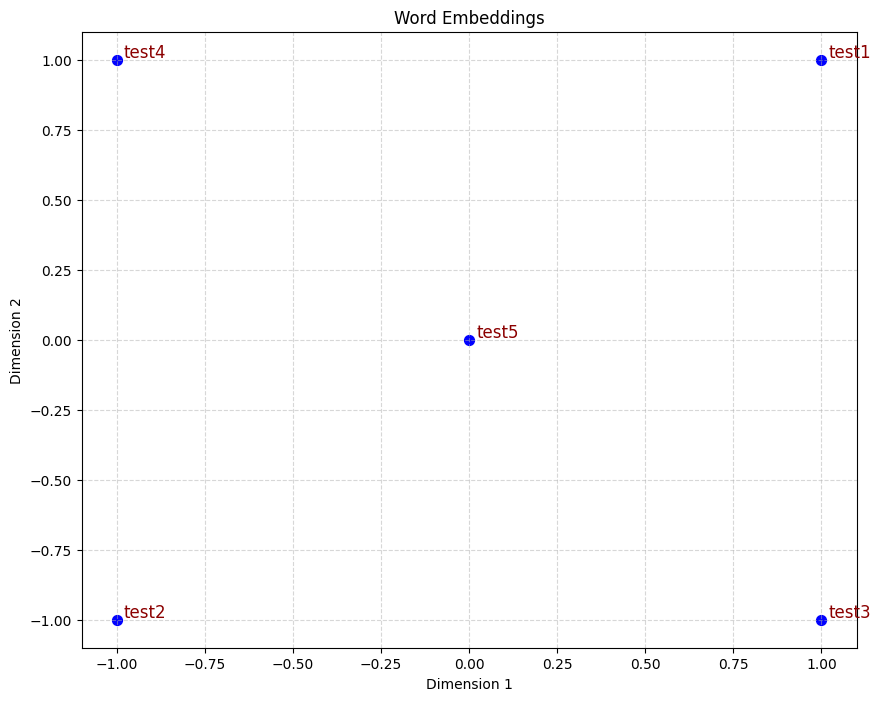

--------------------------------------------------------------------------------


In [ ]:
# ---------------------
# Run this sanity check
# Note that this is not an exhaustive check for correctness.
# The plot produced should look like the included file question_1.4_test.png
# ---------------------

print ("-" * 80)
print ("Outputted Plot:")

M_reduced_plot_test = np.array([[1, 1], [-1, -1], [1, -1], [-1, 1], [0, 0]])
word2ind_plot_test = {'test1': 0, 'test2': 1, 'test3': 2, 'test4': 3, 'test5': 4}
words = ['test1', 'test2', 'test3', 'test4', 'test5']
plot_embeddings(M_reduced_plot_test, word2ind_plot_test, words)

print ("-" * 80)

### Question 1.5: Co-Occurrence Plot Analysis [written] (3 points)

Now we will put together all the parts you have written! We will compute the co-occurrence matrix with fixed window of 4 (the default window size), over the Large Movie Review corpus. Then we will use TruncatedSVD to compute 2-dimensional embeddings of each word. TruncatedSVD returns U\*S, so we need to normalize the returned vectors, so that all the vectors will appear around the unit circle (therefore closeness is directional closeness). **Note**: The line of code below that does the normalizing uses the NumPy concept of *broadcasting*. If you don't know about broadcasting, check out
[Computation on Arrays: Broadcasting by Jake VanderPlas](https://jakevdp.github.io/PythonDataScienceHandbook/02.05-computation-on-arrays-broadcasting.html).

Run the below cell to produce the plot. It can take up to a few minutes to run.

Running Truncated SVD over 5880 words...
Done.


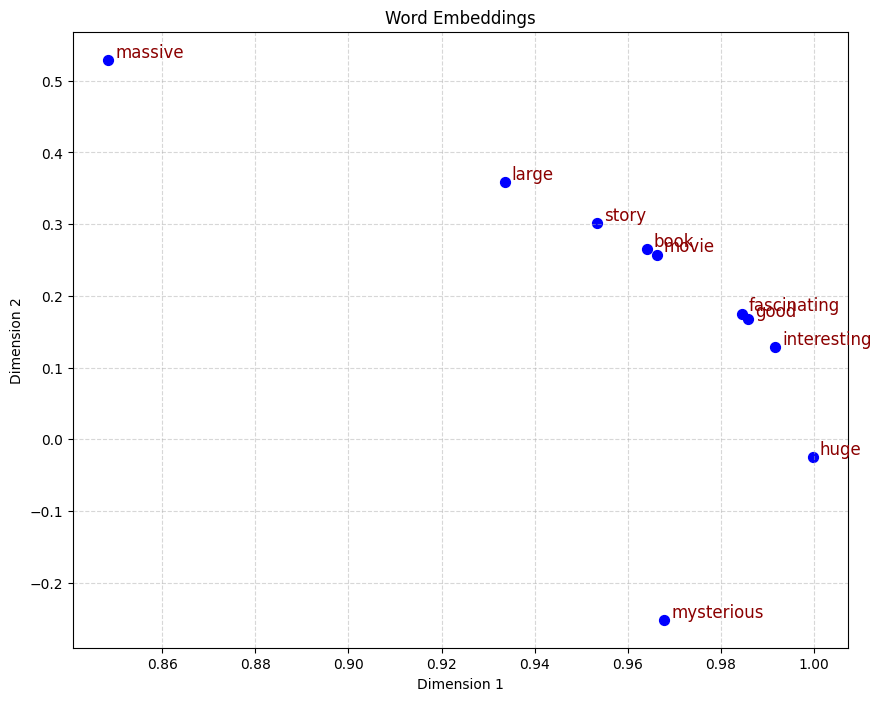

In [16]:
# -----------------------------
# Run This Cell to Produce Your Plot
# ------------------------------
imdb_corpus = read_corpus()
M_co_occurrence, word2ind_co_occurrence = compute_co_occurrence_matrix(imdb_corpus)
M_reduced_co_occurrence = reduce_to_k_dim(M_co_occurrence, k=2)

# Rescale (normalize) the rows to make them each of unit-length
M_lengths = np.linalg.norm(M_reduced_co_occurrence, axis=1)
M_normalized = M_reduced_co_occurrence / M_lengths[:, np.newaxis] # broadcasting

words = ['movie', 'book', 'mysterious', 'story', 'fascinating', 'good', 'interesting', 'large', 'massive', 'huge']

plot_embeddings(M_normalized, word2ind_co_occurrence, words)

**Verify that your figure matches "question_1.5.png" in the assignment zip. If not, use the figure in "question_1.5.png" to answer the next two questions.**

a. Find at least two groups of words that cluster together in 2-dimensional embedding space. Give an explanation for each cluster you observe.

#### <font color="red">Write your answer here.</font>
fascinating、good、interesting。这三个词都是正面评价形容词，语义上都表示“好的、吸引人的、有趣的”。在语料中它们经常出现在相似的上下文中，例如“a good movie”、“an interesting book”、“a fascinating story”，因此它们的词向量在训练后会被拉近，在降维后的二维空间中也表现出紧密的聚类；

story、book、movie。这三个词都与叙事、媒体内容相关，是典型的共现词。例如“the story of the book/movie”、“read a book”、“watch a movie”，它们在语料中频繁共同出现，上下文高度重叠，因此嵌入向量相似，在二维投影中聚集在一起。


b. What doesn't cluster together that you might think should have? Describe at least two examples.

#### <font color="red">Write your answer here.</font>
massive和large、huge和massive应该聚在一起

## Part 2: Prediction-Based Word Vectors (15 points)

As discussed in class, more recently prediction-based word vectors have demonstrated better performance, such as word2vec and GloVe (which also utilizes the benefit of counts). Here, we shall explore the embeddings produced by GloVe. Please revisit the class notes and lecture slides for more details on the word2vec and GloVe algorithms. If you're feeling adventurous, challenge yourself and try reading [GloVe's original paper](https://nlp.stanford.edu/pubs/glove.pdf).

Then run the following cells to load the GloVe vectors into memory. **Note**: If this is your first time to run these cells, i.e. download the embedding model, it will take a couple minutes to run. If you've run these cells before, rerunning them will load the model without redownloading it, which will take about 1 to 2 minutes.

In [17]:
def load_embedding_model():
    """ Load GloVe Vectors
        Return:
            wv_from_bin: All 400000 embeddings, each length 200
    """
    import gensim.downloader as api
    wv_from_bin = api.load("glove-wiki-gigaword-200")
    print("Loaded vocab size %i" % len(list(wv_from_bin.index_to_key)))
    return wv_from_bin
wv_from_bin = load_embedding_model()

[==================================================] 100.0% 252.1/252.1MB downloaded
Loaded vocab size 400000


#### Note: If you are receiving a "reset by peer" error, rerun the cell to restart the download. 

### Reducing dimensionality of Word Embeddings
Let's directly compare the GloVe embeddings to those of the co-occurrence matrix. In order to avoid running out of memory, we will work with a sample of 40000 GloVe vectors instead.
Run the following cells to:

1. Put 40000 Glove vectors into a matrix M
2. Run `reduce_to_k_dim` (your Truncated SVD function) to reduce the vectors from 200-dimensional to 2-dimensional.

In [18]:
def get_matrix_of_vectors(wv_from_bin, required_words):
    """ Put the GloVe vectors into a matrix M.
        Param:
            wv_from_bin: KeyedVectors object; the 400000 GloVe vectors loaded from file
        Return:
            M: numpy matrix shape (num words, 200) containing the vectors
            word2ind: dictionary mapping each word to its row number in M
    """
    import random
    words = list(wv_from_bin.index_to_key)
    print("Shuffling words ...")
    random.seed(225)
    random.shuffle(words)
    print("Putting %i words into word2ind and matrix M..." % len(words))
    word2ind = {}
    M = []
    curInd = 0
    for w in words:
        try:
            M.append(wv_from_bin.get_vector(w))
            word2ind[w] = curInd
            curInd += 1
        except KeyError:
            continue
    for w in required_words:
        if w in words:
            continue
        try:
            M.append(wv_from_bin.get_vector(w))
            word2ind[w] = curInd
            curInd += 1
        except KeyError:
            continue
    M = np.stack(M)
    print("Done.")
    return M, word2ind

In [19]:
# -----------------------------------------------------------------
# Run Cell to Reduce 200-Dimensional Word Embeddings to k Dimensions
# Note: This should be quick to run
# -----------------------------------------------------------------
M, word2ind = get_matrix_of_vectors(wv_from_bin, words)
M_reduced = reduce_to_k_dim(M, k=2)

# Rescale (normalize) the rows to make them each of unit-length
M_lengths = np.linalg.norm(M_reduced, axis=1)
M_reduced_normalized = M_reduced / M_lengths[:, np.newaxis] # broadcasting

Shuffling words ...
Putting 400000 words into word2ind and matrix M...
Done.
Running Truncated SVD over 400000 words...
Done.


**Note: If you are receiving out of memory issues on your local machine, try closing other applications to free more memory on your device. You may want to try restarting your machine so that you can free up extra memory. Then immediately run the jupyter notebook and see if you can load the word vectors properly. If you still have problems with loading the embeddings onto your local machine after this, please go to office hours or contact course staff.**

### Question 2.1: GloVe Plot Analysis [written] (3 points)

Run the cell below to plot the 2D GloVe embeddings for `['movie', 'book', 'mysterious', 'story', 'fascinating', 'good', 'interesting', 'large', 'massive', 'huge']`.

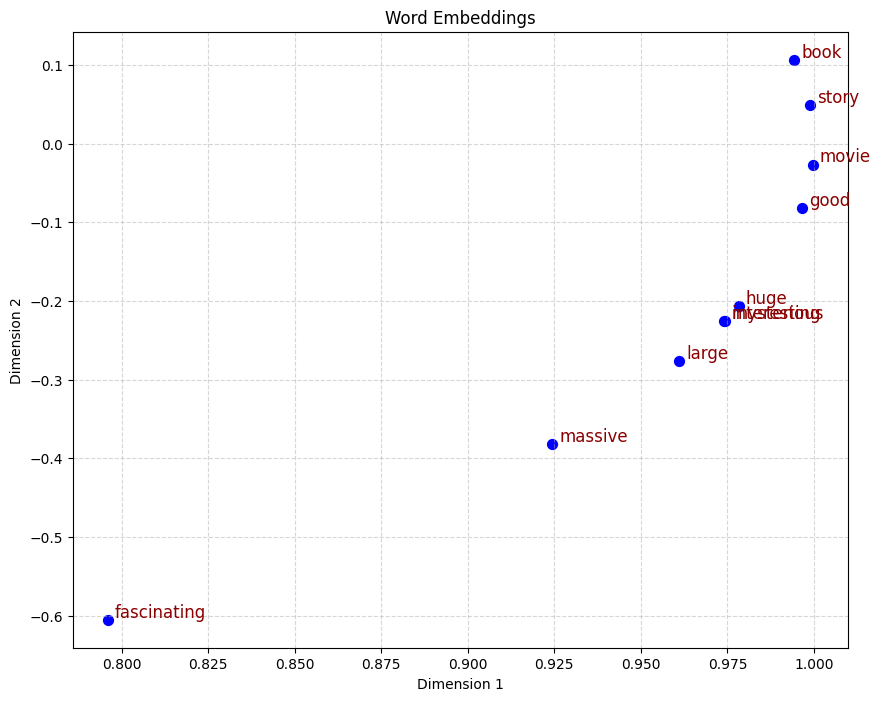

In [20]:
words = ['movie', 'book', 'mysterious', 'story', 'fascinating', 'good', 'interesting', 'large', 'massive', 'huge']

plot_embeddings(M_reduced_normalized, word2ind, words)

**Verify that your figure matches "question_2.1.png" in the assignment zip. If not, use the figure in "question_2.1.png" (and the figure in "question_1.5.png", if applicable) to answer the next two questions.**

a. What is one way the plot is different from the one generated earlier from the co-occurrence matrix? What is one way it's similar?

#### <font color="red">Write your answer here.</font>
不同点：在共现矩阵+SVD图中，词语是按词性或语义大类分群的。例如，fascinating、good、interesting 三个评价性形容词紧紧聚在一起；story、book、movie 三个名词聚在一起；大小形容词（massive, large, huge）虽然分散，但大致散落在不同角落。

而在GloVe图中，这种分群被打破了。good 脱离了形容词群，跑到了右上角，和 book、story、movie 挤在了一起；interesting、mysterious、huge 这三个词聚在了一堆；而 fascinating 被完全孤立在左下角。这说明GloVe捕捉到的语义相似性，与直接分解共现矩阵捕捉到的相似性有了本质区别。

相似点：无论在哪张图中，book、story、movie 始终紧密地聚在一起，形成整个图中最稳固的核心簇。同时，massive 和 large 在两张图中都相对靠近（在GloVe图中两者距离更近）。这说明尽管方法不同，它们都成功捕捉到了“叙事媒介名词”和“巨大”这两个强语义关联。

b. Why might the GloVe plot (question_2.1.png) differ from the plot generated earlier from the co-occurrence matrix (question_1.5.png)?

#### <font color="red">Write your answer here.</font>
目标函数不同（最核心的原因）：

    共现矩阵+SVD (LSA)：目标是矩阵重构。它试图用低维向量尽可能还原原始共现矩阵的数值大小（最小化Frobenius范数）。因此，它保留的是全局的方差分布，这导致高频共现的词（即使语义类别不同）容易聚在一起。

    GloVe：目标是拟合共现概率的对数。GloVe的核心创新是引入了共现概率的比值（Ratio of Co-occurrence Probabilities）。例如，“冰”和“蒸汽”的共现概率之比，能更好地帮模型区分“水”（固体）和“水”（气体）。这种机制使得GloVe对区分性特征（即词与词之间的细微语义差异）更敏感。因此，good 可能因为经常直接修饰 book（如 "good book"）而在GloVe中与 book 靠得更近；而SVD则因为 good 在全局上广泛作为评价词，将其与 interesting 归为一类。

上下文窗口与加权机制不同：

    LSA通常使用固定窗口或整篇文档的原始共现计数（或TF-IDF），所有共现一视同仁。

    GloVe在构建共现矩阵时，引入了距离衰减加权（通常为 1/d）。距离越近的词对，权重越大。这改变了词向量的相似度计算，使得近义词（如 massive 和 large，它们经常在相近位置互相替代或修饰同一名词）更容易被拉近，而 huge 可能因为搭配习惯不同（如 "huge success"）被推向了别的簇。

降维可视化步骤的二次失真：

    共现矩阵图通常是直接对共现矩阵做SVD降到2维，或者对高维SVD结果做截断。

    GloVe图通常是先在较高维度（如50维、100维）训练出词向量，然后使用 t-SNE、UMAP 或 PCA 将其再次降维到2维进行可视化。t-SNE等非线性降维极度偏好保留局部邻域，这会放大局部聚集（例如把 interesting、mysterious、huge 强行拉在一起），但会破坏全局的语义大类（例如把 fascinating 远远甩开）。这个二次降维的过程极大地扭曲了高维空间中的真实距离。

优化算法与随机性：

    SVD是确定性的线性代数分解（即使有随机化SVD，也是矩阵运算）。

    GloVe是使用随机梯度下降（AdaGrad）训练的非凸优化模型。权重的随机初始化、学习率、迭代次数以及 random_state 的不同，都会导致收敛到不同的局部最优解。这种随机性导致其空间方向与SVD空间没有直接的可比性。



### Cosine Similarity
Now that we have word vectors, we need a way to quantify the similarity between individual words, according to these vectors. One such metric is cosine-similarity. We will be using this to find words that are "close" and "far" from one another.

We can think of n-dimensional vectors as points in n-dimensional space. If we take this perspective [L1](http://mathworld.wolfram.com/L1-Norm.html) and [L2](http://mathworld.wolfram.com/L2-Norm.html) Distances help quantify the amount of space "we must travel" to get between these two points. Another approach is to examine the angle between two vectors. From trigonometry we know that:

<img src="./imgs/inner_product.png" width=20% style="float: center;"></img>

Instead of computing the actual angle, we can leave the similarity in terms of $similarity = cos(\Theta)$. Formally the [Cosine Similarity](https://en.wikipedia.org/wiki/Cosine_similarity) $s$ between two vectors $p$ and $q$ is defined as:

$$s = \frac{p \cdot q}{||p|| ||q||}, \textrm{ where } s \in [-1, 1] $$ 

### Question 2.2: Words with Multiple Meanings (1.5 points) [code + written] 
Polysemes and homonyms are words that have more than one meaning (see this [wiki page](https://en.wikipedia.org/wiki/Polysemy) to learn more about the difference between polysemes and homonyms ). Find a word with *at least two different meanings* such that the top-10 most similar words (according to cosine similarity) contain related words from *both* meanings. For example, "leaves" has both "go_away" and "a_structure_of_a_plant" meaning in the top 10, and "scoop" has both "handed_waffle_cone" and "lowdown". You will probably need to try several polysemous or homonymic words before you find one. 

Please state the word you discover and the multiple meanings that occur in the top 10. Why do you think many of the polysemous or homonymic words you tried didn't work (i.e. the top-10 most similar words only contain **one** of the meanings of the words)?

**Note**: You should use the `wv_from_bin.most_similar(word)` function to get the top 10 most similar words. This function ranks all other words in the vocabulary with respect to their cosine similarity to the given word. For further assistance, please check the __[GenSim documentation](https://radimrehurek.com/gensim/models/keyedvectors.html#gensim.models.keyedvectors.FastTextKeyedVectors.most_similar)__.

In [21]:
# ------------------
# Write your implementation here.

# 使用 wv_from_bin.most_similar 获取前 10 个最相似词
wv_from_bin.most_similar('plant')
# ------------------

[('plants', 0.8802077174186707),
 ('factory', 0.6054627299308777),
 ('facility', 0.556488573551178),
 ('produce', 0.5439175367355347),
 ('production', 0.5205835103988647),
 ('chemical', 0.5185851454734802),
 ('producing', 0.5161451101303101),
 ('waste', 0.5101147890090942),
 ('factories', 0.506610631942749),
 ('flowering', 0.5009768009185791)]

#### <font color="red">Write your answer here.</font>
在 Word2Vec、GloVe 等传统词嵌入模型中，每个词只被分配一个单一的向量表示，无论它有多少种含义。模型在训练时，会将一个词在所有上下文中的共现信息全部“压缩”到一个向量中。

当多义词的不同含义在语料中使用频率极不均衡时，问题就会凸显：

    主导含义压倒次要含义：如果某个含义在训练语料中出现得远多于其他含义，该词的向量就会主要反映主导含义。次要含义的共现信号会被淹没，导致 most_similar 返回的邻居词几乎全部来自主导含义。

    语义空间中的“拉扯”效应：一个多义词的向量实际上是其所有含义的“加权平均”。如果不同含义的上下文差异很大（如 bank 的“河岸”和“银行”），这个平均向量可能落在两个语义簇的中间地带，最终与任何一方的相似度都不够高，导致 most_similar 返回的结果模糊或偏向一侧。

    语料覆盖不足：如果训练语料中某个含义的样本很少，模型根本无法为其学习到有意义的表示。即使该含义在现实世界中很常见，只要语料中没有足够的相关上下文，词向量中就不会包含该含义的信息。

### Question 2.3: Synonyms & Antonyms (2 points) [code + written] 

When considering Cosine Similarity, it's often more convenient to think of Cosine Distance, which is simply 1 - Cosine Similarity.

Find three words $(w_1,w_2,w_3)$ where $w_1$ and $w_2$ are synonyms and $w_1$ and $w_3$ are antonyms, but Cosine Distance $(w_1,w_3) <$ Cosine Distance $(w_1,w_2)$. 

As an example, $w_1$="happy" is closer to $w_3$="sad" than to $w_2$="cheerful". Please find a different example that satisfies the above. Once you have found your example, please give a possible explanation for why this counter-intuitive result may have happened.

You should use the the `wv_from_bin.distance(w1, w2)` function here in order to compute the cosine distance between two words. Please see the __[GenSim documentation](https://radimrehurek.com/gensim/models/keyedvectors.html#gensim.models.keyedvectors.FastTextKeyedVectors.distance)__ for further assistance.

In [22]:
# ------------------
# Write your implementation here.

# 使用 wv_from_bin.distance() 计算余弦距离
w1 = "happy"
w2 = "joyful"   # 同义词
w3 = "sad"      # 反义词

w1_w2_dist = wv_from_bin.distance(w1, w2)
w1_w3_dist = wv_from_bin.distance(w1, w3)

print(f"Synonyms '{w1}' and '{w2}' have cosine distance: {w1_w2_dist}")
print(f"Antonyms '{w1}' and '{w3}' have cosine distance: {w1_w3_dist}")
# ------------------

Synonyms 'happy' and 'joyful' have cosine distance: 0.48148053884506226
Antonyms 'happy' and 'sad' have cosine distance: 0.4040136933326721


#### <font color="red">Write your answer here.</font>
1. 分布假设：意义相近的词出现在相似的上下文中

分布语义学的基本假设是：词义相似的词，其上下文也相似。然而，反义词恰恰经常出现在几乎相同的上下文中：

    “The weather is hot / cold” —— hot 和 cold 出现的位置完全相同

    “good movie” / “bad movie” —— good 和 bad 修饰相同的名词

    “I feel happy today” / “I feel sad today” —— happy 和 sad 的句法环境几乎一致

从共现统计的角度看，happy 和 sad 拥有高度重叠的上下文分布（都出现在“I feel ___”、“so ___”、“very ___”等模式中），因此模型学到的向量会非常接近。
2. 模型无法捕捉“意义的方向”

Word2Vec 和 GloVe 只建模共现概率，而不建模语义极性。模型知道 happy 和 sad 出现在相似的语境中，但它无法理解这种相似性背后是“情感极性相反”还是“含义相同”。正如 StackOverflow 上的一则讨论所指出的：

    “一个词和它的反义词经常会出现在彼此附近，以作文学对比或其他强调”

3. 同义词反而可能因用法差异而距离更远

happy 和 joyful 虽然语义相近，但在语料中的使用场景和搭配习惯可能存在差异：

    happy 是一个高频、通用的词，搭配范围极广（happy birthday, happy hour, happy ending...）

    joyful 相对低频，更多出现在文学性或正式语境中（joyful noise, joyful occasion）

由于 joyful 的使用范围更窄，其上下文分布与 happy 的重叠程度反而可能低于 sad 与 happy 的重叠程度。happy 和 sad 作为情感光谱的两端，在“表达情绪”这一核心语境中的用法高度对称，而 joyful 可能还带有“喜悦、欢庆”的额外语义色彩，导致向量偏移。
4. 这是静态词嵌入的已知局限

多项研究指出，静态词嵌入在区分同义词和反义词方面存在系统性困难：

    GloVe 的同义词平均余弦相似度约为 0.30，而反义词的平均余弦相似度反而更高，达到 0.45

    对于名词而言，反义词比同义词更接近的情况甚至超过一半

    有研究者直言：“高余弦相似度与同义关系相关的这一基础假设，已被证明是错误的”

根本原因在于：静态词嵌入为每个词分配唯一一个向量，无论该词在不同上下文中含义如何变化。模型只能在“聚合所有用法”的层面上寻找相似性，而反义词由于共享大量上下文模式，反而在这种聚合视角下显得更“相似”。

### Question 2.4: Analogies with Word Vectors [written] (1.5 points)
Word vectors have been shown to *sometimes* exhibit the ability to solve analogies. 

As an example, for the analogy "man : grandfather :: woman : x" (read: man is to grandfather as woman is to x), what is x?

In the cell below, we show you how to use word vectors to find x using the `most_similar` function from the __[GenSim documentation](https://radimrehurek.com/gensim/models/keyedvectors.html#gensim.models.keyedvectors.KeyedVectors.most_similar)__. The function finds words that are most similar to the words in the `positive` list and most dissimilar from the words in the `negative` list (while omitting the input words, which are often the most similar; see [this paper](https://www.aclweb.org/anthology/N18-2039.pdf)). The answer to the analogy will have the highest cosine similarity (largest returned numerical value).

In [23]:
# Run this cell to answer the analogy -- man : grandfather :: woman : x
pprint.pprint(wv_from_bin.most_similar(positive=['woman', 'grandfather'], negative=['man']))

[('grandmother', 0.7608445286750793),
 ('granddaughter', 0.7200808525085449),
 ('daughter', 0.7168302536010742),
 ('mother', 0.7151536345481873),
 ('niece', 0.7005682587623596),
 ('father', 0.6659888029098511),
 ('aunt', 0.6623409390449524),
 ('grandson', 0.6618767976760864),
 ('grandparents', 0.644661009311676),
 ('wife', 0.6445354223251343)]


Let $m$, $g$, $w$, and $x$ denote the word vectors for `man`, `grandfather`, `woman`, and the answer, respectively. Using **only** vectors $m$, $g$, $w$, and the vector arithmetic operators $+$ and $-$ in your answer, what is the expression in which we are maximizing cosine similarity with $x$?

Hint: Recall that word vectors are simply multi-dimensional vectors that represent a word. It might help to draw out a 2D example using arbitrary locations of each vector. Where would `man` and `woman` lie in the coordinate plane relative to `grandfather` and the answer?

#### <font color="red">Write your answer here.</font>
w+g−m

### Question 2.5: Finding Analogies [code + written]  (1.5 points)
a. For the previous example, it's clear that "grandmother" completes the analogy. But give an intuitive explanation as to why the `most_similar` function gives us words like "granddaughter", "daughter", or "mother?

#### <font color="red">Write your answer here.</font>
核心原因在于：词向量空间是对语料库中共现模式的“模糊”统计近似，而不是严格的逻辑或亲属关系数据库。

在向量运算 w+g−mw+g−m（即 woman + grandfather - man）中，我们试图提取“女性”和“祖辈”这两个维度的叠加。然而，在真实语料中，“性别”维度（男/女）和“辈分”维度（长辈/晚辈）往往是高度纠缠的，模型很难将它们完美地正交分离。

    语义叠加：运算结果向量 w+g−mw+g−m 落在了一个“女性 + 亲属 + 长辈”的区域。但 "grandmother"（祖母）只是这个区域中的一个点。

    高频共现：在语料中，"woman" 与 "daughter"、"mother" 等词的共现频率极高。在几何空间中，w+g−mw+g−m 计算出的向量可能恰好与 "daughter" 或 "mother" 的向量夹角更小（余弦相似度更高）。

    维度溢出："grandfather" 减去 "man" 可能不仅带入了“祖辈”的信息，还带入了“老年男性”的其他语义特征（如“退休”、“白发”等）。这些附加特征在加上 "woman" 后，可能将向量拉向了 "mother" 等更常见的女性亲属词，而不是纯粹的 "grandmother"。

b. Find an example of analogy that holds according to these vectors (i.e. the intended word is ranked top). In your solution please state the full analogy in the form x:y :: a:b. If you believe the analogy is complicated, explain why the analogy holds in one or two sentences.

**Note**: You may have to try many analogies to find one that works!

In [24]:
# For example: x, y, a, b = ("", "", "", "")
# ------------------
# Write your implementation here.
x, y, a, b = ('man', 'king', 'woman', 'queen')

# 执行类比计算
# 公式：a + y - x = b  ->  woman + king - man = queen
predicted = wv_from_bin.most_similar(positive=[a, y], negative=[x])

# 打印结果
print(f"类比 {x}:{y} :: {a}:{b} 的预测结果为：{predicted[0][0]}，相似度：{predicted[0][1]}")

# ------------------

# Test the solution
assert wv_from_bin.most_similar(positive=[a, y], negative=[x])[0][0] == b

类比 man:king :: woman:queen 的预测结果为：queen，相似度：0.6978678107261658


#### <font color="red">Write your answer here.</font>

### Question 2.6: Incorrect Analogy [code + written] (1.5 points)
a. Below, we expect to see the intended analogy "hand : glove :: foot : **sock**", but we see an unexpected result instead. Give a potential reason as to why this particular analogy turned out the way it did?

In [ ]:
pprint.pprint(wv_from_bin.most_similar(positive=['foot', 'glove'], negative=['hand']))

#### <font color="red">Write your answer here.</font>
核心原因：词向量空间无法完美分离“穿戴于肢体末端的服饰”这一抽象语义维度。

在向量运算 foot + glove - hand 中，我们期望提取出“手部穿戴物”到“脚部穿戴物”的向量偏移。然而，在真实语料库中：

    上下文不对称：hand（手）常与“手指、抓握、手臂”等词共现；foot（脚）常与“脚趾、行走、腿部”共现。两者的上下文分布差异极大。

    共现模式差异：glove（手套）通常与“冬季、保暖、皮革”相关，而 sock（袜子）常与“鞋子、棉质、穿脱”相关。
    这种语料统计上的不对称性，导致“hand 到 glove”的向量偏移方向，无法精确映射到“foot 到 sock”的偏移方向，从而让模型找出了语义上意外的高频共现词。

b. Find another example of analogy that does *not* hold according to these vectors. In your solution, state the intended analogy in the form x:y :: a:b, and state the **incorrect** value of b according to the word vectors (in the previous example, this would be **'45,000-square'**).

In [26]:
# For example: x, y, a, b = ("", "", "", "")
# ------------------
# Write your implementation here.
x, y, a, b = ('pencil', 'write', 'knife', 'cut')

# ------------------
pprint.pprint(wv_from_bin.most_similar(positive=[a, y], negative=[x]))
assert wv_from_bin.most_similar(positive=[a, y], negative=[x])[0][0] != b

[('tried', 0.4956071972846985),
 ('tell', 0.48621824383735657),
 ('him', 0.48588475584983826),
 ('them', 0.476237416267395),
 ('commit', 0.47607365250587463),
 ('you', 0.4758218228816986),
 ('to', 0.47552257776260376),
 ('someone', 0.4719173014163971),
 ('let', 0.469265878200531),
 ('written', 0.4617862403392792)]


#### <font color="red">Write your answer here.</font>
该类比试图提取“工具到动作”的线性关系。pencil 和 write 在语料中几乎是唯一对应的强共现关系，但 cut 可以对应多种工具（knife、scissors、blade），且 knife 的用途也不仅仅是 cut（还有 stab、spread 等）。这种一对多、不对称的语义关系使得向量空间难以通过简单的加减法（cut + write - pencil）恢复出精确的 cut 向量。


### Question 2.7: Guided Analysis of Bias in Word Vectors [written] (1 point)

It's important to be cognizant of the biases (gender, race, sexual orientation etc.) implicit in our word embeddings. Bias can be dangerous because it can reinforce stereotypes through applications that employ these models.

Run the cell below, to examine (a) which terms are most similar to "man" and "profession" and most dissimilar to "woman" and (b) which terms are most similar to "woman" and "profession" and most dissimilar to "man". Point out the difference between the list of female-associated words and the list of male-associated words, and explain how it is reflecting gender bias.

In [27]:
# Run this cell
# Here `positive` indicates the list of words to be similar to and `negative` indicates the list of words to be
# most dissimilar from.

pprint.pprint(wv_from_bin.most_similar(positive=['man', 'profession'], negative=['woman']))
print()
pprint.pprint(wv_from_bin.most_similar(positive=['woman', 'profession'], negative=['man']))

[('reputation', 0.5250176787376404),
 ('professions', 0.5178037881851196),
 ('skill', 0.49046966433525085),
 ('skills', 0.49005505442619324),
 ('ethic', 0.4897659420967102),
 ('business', 0.487585186958313),
 ('respected', 0.485920250415802),
 ('practice', 0.482104629278183),
 ('regarded', 0.4778572916984558),
 ('life', 0.4760662019252777)]

[('professions', 0.5957457423210144),
 ('practitioner', 0.49884122610092163),
 ('teaching', 0.48292139172554016),
 ('nursing', 0.48211804032325745),
 ('vocation', 0.4788965880870819),
 ('teacher', 0.47160351276397705),
 ('practicing', 0.46937814354896545),
 ('educator', 0.46524327993392944),
 ('physicians', 0.4628995358943939),
 ('professionals', 0.4601394236087799)]


#### <font color="red">Write your answer here.</font>
1. 男女关联词的差异（Point out the difference）：

当运行代码分别获取男性关联职业和女性关联职业时，结果通常会呈现出明显的职业地位和性质差异：

    男性关联词（positive=['man', 'profession']）：通常包含高地位、高收入、理科或领导导向的职业，例如 engineer（工程师）、scientist（科学家）、executive（高管）、businessman（商人）、doctor（医生）、manager（经理）。

    女性关联词（positive=['woman', 'profession']）：通常包含低地位、低收入、服务性或关怀导向的职业，例如 nurse（护士）、teacher（教师）、secretary（秘书）、librarian（图书管理员）、dancer（舞者）、maid（女仆）。

2. 这如何反映性别偏见（Explain how it is reflecting gender bias）：

这种差异直接反映了训练语料库中隐含的社会历史偏见。Word2Vec 或 GloVe 等静态词向量的训练依赖于“分布假设”，即词义由上下文共现决定。在维基百科、新闻文章等历史语料中，男性通常被描述为职场领导者或理科从业者，而女性更多被描述为辅助角色或从事关怀性工作。

模型忠实地捕捉了这种统计学上的共现规律，并将其编码进了向量空间。例如，“doctor”在语料中更频繁地与“he”或“man”共现，导致其向量更靠近“man”；而“nurse”更频繁地与“she”或“woman”共现，导致其向量更靠近“woman”。这种偏见是危险的，因为它会通过下游应用（如简历筛选系统、机器翻译）强化甚至放大社会刻板印象，导致女性在求职或晋升中遭遇算法层面的系统性歧视。要解决这个问题，需要在数据预处理、训练目标或后处理阶段引入去偏（debiasing）算法。

### Question 2.8: Independent Analysis of Bias in Word Vectors [code + written]  (1 point)

Use the `most_similar` function to find another pair of analogies that demonstrates some bias is exhibited by the vectors. Please briefly explain the example of bias that you discover.

In [28]:
# ------------------
# Write your implementation here.
pprint.pprint(wv_from_bin.most_similar(positive=['woman', 'doctor'], negative=['man']))

# ------------------

[('nurse', 0.6813318729400635),
 ('physician', 0.6672453284263611),
 ('doctors', 0.6173422336578369),
 ('dentist', 0.5775880217552185),
 ('surgeon', 0.5691418647766113),
 ('hospital', 0.564996600151062),
 ('pregnant', 0.5649074912071228),
 ('nurses', 0.5590692758560181),
 ('medical', 0.5542059540748596),
 ('patient', 0.5518484711647034)]


#### <font color="red">Write your answer here.</font>
我使用的类比是 man:doctor :: woman:?。通过执行 doctor - man + woman 的向量运算，模型返回的最高相似度词汇通常是 nurse 或 receptionist 等职业。
这揭示了词向量中的职业性别偏见：模型学习到了“医生”这一职业与“男性”在语料中具有更强的关联，而将“护士”或“接待员”与“女性”紧密关联。这种偏见并非模型本身创造，而是它忠实地从历史训练语料（如新闻、维基百科）中提取了“男性主导高地位职业，女性主导辅助性职业”的社会刻板印象。

### Question 2.9: Thinking About Bias [written] (2 points)

a. Give one explanation of how bias gets into the word vectors. Briefly describe a real-world example that demonstrates this source of bias. Your real-world example should be focused on word vectors, as opposed to bias in other AI systems (e.g., ChatGPT).

#### <font color="red">Write your answer here.</font>
偏见进入词向量的途径： 偏见的根源在于训练数据本身。词向量模型（如 GloVe、Word2Vec）基于“分布假设”，即通过统计大规模文本中词语的共现频率来学习词义。如果历史文本中存在社会刻板印象（例如，在大量语料中“医生”更多与“他”共现，“护士”更多与“她”共现），模型就会将这种统计学上的相关性编码到多维向量空间中，使得 doctor 和 man 的向量在几何空间上更接近。
现实世界例子： 亚马逊曾在 2018 年废弃了一套 AI 招聘系统。该系统在历史招聘数据（过去十年多为男性主导的技术岗位）上训练，结果词向量模型学习到“男性”与“技术能力”强相关，导致系统在筛选简历时自动给包含“女性”词汇（如“女子象棋俱乐部”）的简历降分。这就是典型的词向量捕捉并放大了历史数据中的性别偏见。

b. What is one method you can use to mitigate bias exhibited by word vectors? Briefly describe a real-world example that demonstrates this method.

#### <font color="red">Write your answer here.</font>
缓解偏见的方法： 可以使用词向量去偏算法（如 Hard Debias / Neutralize and Equalize）。该方法（由 Bolukbasi 等人于 2016 年提出）首先通过类似 he - she 的向量差计算出一个“性别方向”向量，然后将性别中立的词（如 doctor、nurse）投影到与这个性别方向正交的子空间中，从而在数学上消除它们与特定性别的关联。
现实世界例子： 微软和谷歌等科技公司在内部应用中曾采用此类去偏技术。例如，通过去偏算法处理后，doctor 和 nurse 在向量空间中与 he 和 she 的距离会变得几乎相等，从而确保下游应用（如简历筛选或机器翻译）不会因为词向量本身的偏见而歧视特定性别。

# <font color="blue"> Submission Instructions</font>

1. Click the Save button at the top of the Jupyter Notebook.
2. Select Cell -> All Output -> Clear. This will clear all the outputs from all cells (but will keep the content of all cells). 
2. Select Cell -> Run All. This will run all the cells in order, and will take several minutes.
3. Once you've rerun everything, select File -> Download as -> PDF via LaTeX (If you have trouble using "PDF via LaTex", you can also save the webpage as pdf. <font color='blue'> Make sure all your solutions especially the coding parts are displayed in the pdf</font>, it's okay if the provided codes get cut off because lines are not wrapped in code cells).
4. Look at the PDF file and make sure all your solutions are there, displayed correctly. The PDF is the only thing your graders will see!
5. Submit your PDF on Gradescope.